# TRANSFORMACIÓN DE DATOS

## IMPORTAR PAQUETES

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
import os
from pathlib import Path
import openpyxl
import sqlalchemy as sa

# Desactivar notación científica
pd.set_option('display.float_format', lambda x: '%.3f' % x)
np.set_printoptions(suppress=True)

#RUTAS
# ── Rutas del proyecto ────────────────────────────────────────────────
# Se resuelven desde la ubicación del notebook, así funcionan
# igual en cualquier máquina
RAIZ = Path.cwd().parent

ORIGINALES   = RAIZ / '02_datos' / '01_Originales'
VALIDACION   = RAIZ / '02_datos' / '02_Validacion'
ENTRENAMIENTO = RAIZ / '02_datos' / '03_Entrenamiento'
CACHES       = RAIZ / '02_datos' / '04_Caches'
MODELOS      = RAIZ / '05_modelos'
RESULTADOS   = RAIZ / '06_resultados'

# ----------USO DE UTILS.PY------------
import sys
from pathlib import Path
# Subir de 03_notebooks a 03_RIESGOS
ROOT = Path.cwd().parent
# Añadir 04_scripts a las rutas de búsqueda
sys.path.insert(0, str(ROOT / "04_scripts"))
#---------------------------------------

# Cargar variables de entorno
load_dotenv()

print("✅ Librerías importadas correctamente")

✅ Librerías importadas correctamente


## IMPORTAR LOS DATOS

In [2]:
cat = pd.read_pickle(ENTRENAMIENTO / 'cat_eda.pkl')
num = pd.read_pickle(ENTRENAMIENTO / 'num_eda.pkl')

Recordamos lo que habíamos identificado en fases anteriores y lo organizamos por tipo de acción.

Modificar con pandas/numpy:

* Crear la target a partir de estado
* Discretizar num_meses_desde_ult_retraso
* En vivienda juntar ANY, NONE y OTHER
* En finalidad juntar renewable_energy, educational y wedding en 'otros'

Modificar con scikit learn:

* Convertir num_derogatorios a binaria

## CREACIÓN DE VARIABLES Y TRANSFORMACIONES CON PANDAS

### Target para el modelo PD

Crear la target a partir de estado

In [3]:
cat['estado'].value_counts()

estado
Fully Paid                                             66459
Current                                                54347
Charged Off                                            16490
Late (31-120 days)                                      1336
In Grace Period                                          522
Late (16-30 days)                                        272
Does not meet the credit policy. Status:Fully Paid       117
Does not meet the credit policy. Status:Charged Off       56
Default                                                    3
Name: count, dtype: int64

In [4]:
lista_estados = ['Charged Off','Does not meet the credit policy. Status:Charged Off', 'Default']  # Reemplaza con los estados que consideres como positivos
cat['target_pd'] = np.where(cat['estado'].isin(lista_estados), 1, 0)

In [5]:
#Anotar en el informe - para evitar data leakage, se elimina la columna 'estado' del DataFrame cat,
#ademas de que en produccion no se contara con esta informacion
cat.drop('estado', axis=1, inplace=True)

### Target para el modelo EAD

**Definición de la variable objetivo (`target_ead`)**

La variable `target_ead` representa el porcentaje del principal que aún no ha sido amortizado (es decir, la **exposición al pago** pendiente). Se calcula restando lo ya pagado al principal original y dividiendo el resultado entre dicho principal:

$$\text{target\_ead} = \frac{\text{Principal} - \text{Pagado}}{\text{Principal}}$$

**¿Por qué se crea en valores relativos (entre 0 y 1) y no en importe absoluto?**

1. **Para corregir errores de las regresiones y acotar valores extremos:** Al predecir importes directos, una regresión puede descontrolarse o toparse con anomalías donde la deuda pendiente supera al préstamo inicial (por ejemplo, un principal de **10.000** con un pendiente de **15.000**). Al pasarlo a tanto por uno, podemos recortar fácilmente (`clip`) la variable `target_ead` a la baja en **0** y a la alta en **1**, evitando que el modelo aprenda o prediga valores imposibles.


2. **Para estandarizar el peso real de cada préstamo:** Permite que el modelo evalúe préstamos de distinto tamaño bajo la misma escala. Por ejemplo, si tenemos un préstamo de **100.000** y otro de **50.000**, y en ambos el modelo predice un `target_ead` del **25 %** (`0.25`), luego basta con multiplicar esa predicción por el principal de cada uno para recuperar su exposición real en dinero absoluto (**25.000** y **12.500**, respectivamente):

$$\text{EAD absoluta} = \text{target\_ead} \times \text{Principal}$$

In [6]:
num['pendiente'] = num['principal'] - num['imp_amortizado']

In [7]:
num['target_ead'] = num['pendiente']/num['principal']

### Target para el modelo LGD

**Definición de la variable objetivo (`target_lgd`)**

La variable `target_lgd` representa el porcentaje de la deuda pendiente que **no se logra recuperar** en caso de impago (la pérdida real sobre la exposición). Se calcula restando a 1 la proporción del importe recuperado sobre el saldo pendiente:

$$\text{target\_lgd} = 1 - \frac{\text{Importe recuperado}}{\text{Pendiente}}$$

* **Tratamiento de nulos:** Cuando el importe `pendiente` es **0**, la división por cero genera valores nulos (`NaN`). Como no existe deuda pendiente que perder, se imputan directamente con **0**.

In [8]:
num['target_lgd'] = 1 -(num['imp_recuperado'] / num['pendiente'])

In [9]:
num['target_lgd'] = num['target_lgd'].fillna(0)

Comprobamos las targets creadas.

In [10]:
cat[['target_pd']].describe().T

,count,mean,std,min,25%,50%,75%,max
target_pd,139602.000,0.119,0.323,0.000,0.000,0.000,0.000,1.000


tasa de impago del 12% , desde el punto de negocio se podria comparar :
- tasa vs otros bancos
- tasa vs otros momentos temporales

In [11]:
num[['target_ead','target_lgd']].describe().T

,count,mean,std,min,25%,50%,75%,max
target_ead,139602.000,0.337,0.369,-0.000,0.000,0.129,0.725,1.000
target_lgd,139602.000,0.509,0.490,-0.276,0.000,0.851,1.000,1.000


In [12]:
#Limitamos para garantizar que siempre estén entre 0 y 1
num['target_ead'] = num['target_ead'].clip(0, 1)
num['target_lgd'] = num['target_lgd'].clip(0, 1)

### Resto de variables

num_meses_desde_ult_retraso

Vamos a comenzar revisando la relación con la target_pd

In [13]:
#Para completar 20 intervalos discretizando las variables
temp = num[['num_meses_desde_ult_retraso']].copy()
temp['num_meses_desde_ult_retraso_tramo'] = pd.cut(temp['num_meses_desde_ult_retraso'],20)

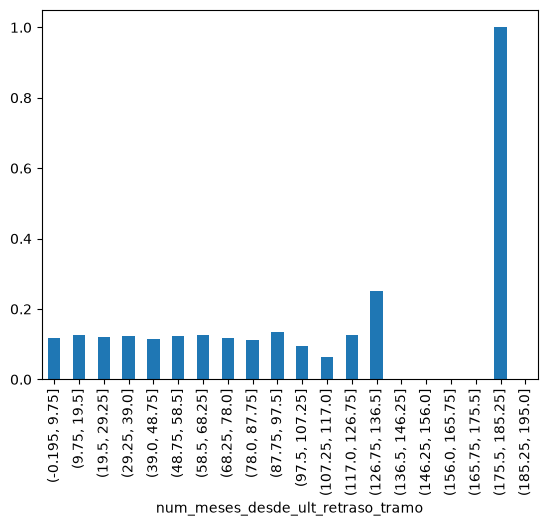

In [14]:
# Para comprar penetracion entre meses de retraso y la target de default
temp['target_pd'] = cat['target_pd']
temp.groupby(
    'num_meses_desde_ult_retraso_tramo',
    observed=False
)['target_pd'].mean().plot(kind='bar');

In [15]:
resumen = temp.groupby(
    'num_meses_desde_ult_retraso_tramo',
    observed=False
)['target_pd'].agg(['count', 'sum', 'mean'])

resumen

,count,sum,mean
num_meses_desde_ult_retraso_tramo,,,
"(-0.195, 9.75]",80673,9396,0.116
"(9.75, 19.5]",11971,1521,0.127
"(19.5, 29.25]",10888,1296,0.119
"(29.25, 39.0]",9940,1228,0.124
"(39.0, 48.75]",8072,915,0.113
"(48.75, 58.5]",6065,746,0.123
"(58.5, 68.25]",5561,697,0.125
"(68.25, 78.0]",4890,575,0.118
"(78.0, 87.75]",1406,159,0.113


La variable `num_meses_desde_ult_retraso` no parece aportar capacidad discriminativa respecto a `target_pd`. Al discretizarla en tramos y comparar la tasa de default, los intervalos con un número suficiente de préstamos presentan proporciones similares, en torno al 11–13 %.

Se descarta esta variable como candidata predictora en esta fase. Esta decisión podrá contrastarse en la preselección mediante *mutual information* de hacerse y, posteriormente, con el rendimiento del modelo.

In [16]:
num.drop(columns='num_meses_desde_ult_retraso',inplace=True)

## TRANSFORMACIÓN DE CATEGÓRICAS

En vivienda juntar ANY, NONE y OTHER
En finalidad juntar renewable_energy, educational y wedding en 'otros'

De cara a aplicar OHE

In [17]:
cat['vivienda'] = cat['vivienda'].replace(['ANY','NONE','OTHER'],'MORTGAGE')

In [18]:
cat['finalidad'] = cat['finalidad'].replace(['wedding','educational','renewable_energy'],'other')

### One Hot Encoding

#### Variables a aplicar OHE

In [19]:
lista = cat.columns
for n in lista :
    print(cat[n].value_counts())

antiguedad_empleo
10+ years      45941
2 years        12501
< 1 year       11863
3 years        11185
1 year          9104
Desconocido     9047
5 years         8700
4 years         8524
6 years         6309
7 years         5783
8 years         5730
9 years         4915
Name: count, dtype: int64
ingresos_verificados
Source Verified    54511
Not Verified       46292
Verified           38799
Name: count, dtype: int64
rating
B    41021
C    40044
A    26814
D    19946
E     8385
F     2621
G      771
Name: count, dtype: int64
vivienda
MORTGAGE    68549
RENT        55438
OWN         15615
Name: count, dtype: int64
finalidad
debt_consolidation    79151
credit_card           31557
home_improvement       9123
other                  8865
major_purchase         3189
medical                1723
small_business         1632
car                    1429
moving                 1003
vacation                996
house                   934
Name: count, dtype: int64
num_cuotas
36 months    99732
60 months

#### Instanciar

In [20]:
#Variables a one-hot encodear
vars_to_onehot = ['ingresos_verificados','vivienda','finalidad','num_cuotas']

In [21]:
from sklearn.preprocessing import OneHotEncoder
onehot = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

#### Entrenar y aplicar

In [22]:
cat_ohe = onehot.fit_transform(cat[vars_to_onehot])
cat_ohe = pd.DataFrame(cat_ohe, columns=onehot.get_feature_names_out(vars_to_onehot))

### Ordinal Encoding

#### Variables a aplicar OE

In [23]:
# Orden de menor a mayor antigüedad. Los textos deben ser IGUALES a los de los datos.
orden_antiguedad_empleo = ['Desconocido', '< 1 year', '1 year', '2 years', '3 years',
                           '4 years', '5 years', '6 years', '7 years', '8 years',
                           '9 years', '10+ years']

# Orden del rating: de mejor (A) a peor (G)
orden_rating = ['A', 'B', 'C', 'D', 'E', 'F', 'G']

vars_to_ordinal = ['antiguedad_empleo', 'rating']

#### Instanciar

In [24]:
from sklearn.preprocessing import OrdinalEncoder
cat_oe = OrdinalEncoder(categories=[orden_antiguedad_empleo, orden_rating],handle_unknown='use_encoded_value',
                        unknown_value=12)

#### Entrenar y aplicar

In [25]:
cat_oe = cat_oe.fit_transform(cat[vars_to_ordinal])
cat_oe = pd.DataFrame(cat_oe, columns=vars_to_ordinal)

## TRANSFORMACIÓN DE NUMÉRICAS

### Binarizar variables

#### Instanciar

In [26]:
from sklearn.preprocessing import Binarizer
num_bin = Binarizer(threshold=0).fit_transform(num[['num_derogatorios']])
num_bin = pd.DataFrame(num_bin, columns=['num_derogatorios'])

In [27]:
num_bin.value_counts()

num_derogatorios
0                   117439
1                    22163
Name: count, dtype: int64

## REESCALAR VARIABLES

### Con Min-Max

Unificar los datasets a reescalar.

In [28]:
num_escalar = num[['ingresos',
                   'dti',
                   'num_lineas_credito',
                   'porc_uso_revolving',
                   'principal',
                   'tipo_interes',
                   'imp_cuota']].reset_index(drop=True)

#### Variables a reescalar con Min-Max

In [29]:
#Se concatenan las variables categoricas ordinales con las variables numericas a escalar, ya que
# aquellas categoricas que se les aplico onehot encodings, ya cuentan con sus valores entre 0 y 1.
df_res = pd.concat([cat_oe,num_escalar ], axis=1)
var_mms = df_res.columns.tolist()

#### Instanciar, entrenar y aplicar y guardar como dataframe

In [30]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
num_escalar_scaled = scaler.fit_transform(df_res[var_mms])
#añadir sufijos a los nombres
var_mms = [col + '_scaled' for col in var_mms]
df_mms = pd.DataFrame(num_escalar_scaled, columns=var_mms)

## UNIFICAR DATASETS

### Construcción del tablón analítico para el modelo de PD

Se reúnen las variables transformadas, el identificador del cliente y la variable objetivo `target_pd`. Se reinician los índices para concatenar los dataframes por posición, manteniendo el orden original de los préstamos. `id_cliente` se conserva para trazabilidad, pero no debe incluirse entre las variables predictoras del modelo.

In [31]:
# Extraer la columna 'id_cliente' del dataframe num y reiniciar el índice
id_cliente = num[['id_cliente']].reset_index(drop=True)

# Concatenar las variables categóricas codificadas, las variables numéricas escaladas y las variables binarias en un solo dataframe X_pd
X_pd = pd.concat(
    [
        cat_ohe.reset_index(drop=True),
        df_mms.reset_index(drop=True),
        num_bin.reset_index(drop=True)
    ],
    axis=1
)

# Extraer la variable objetivo 'target_pd' del dataframe cat y reiniciar el índice
y_pd = cat['target_pd'].reset_index(drop=True).rename('target_pd')

# Verificar que todas las longitudes de los dataframes coincidan
assert len(id_cliente) == len(X_pd) == len(y_pd)

# Concatenar id_cliente, X_pd y y_pd en un solo dataframe final tabla_pd
tabla_pd = pd.concat([id_cliente, X_pd, y_pd], axis=1)

In [32]:
# Establecer la columna 'id_cliente' como índice del dataframe final tabla_pd
tabla_pd.set_index('id_cliente', inplace=True)

# Verificar que la columna 'id_cliente' se haya establecido correctamente como índice
assert tabla_pd.index.name == 'id_cliente'

# Verificar que no haya valores nulos en el índice
assert tabla_pd.index.isnull().sum() == 0

tabla_pd

,ingresos_verificados_Not Verified,ingresos_verificados_Source Verified,ingresos_verificados_Verified,vivienda_MORTGAGE,vivienda_OWN,vivienda_RENT,finalidad_car,finalidad_credit_card,finalidad_debt_consolidation,finalidad_home_improvement,...,rating_scaled,ingresos_scaled,dti_scaled,num_lineas_credito_scaled,porc_uso_revolving_scaled,principal_scaled,tipo_interes_scaled,imp_cuota_scaled,num_derogatorios,target_pd
id_cliente,,,,,,,,,,,,,,,,,,,,,
4798121,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,...,0.500,0.163,0.254,0.165,0.862,0.241,0.485,0.207,0,1
46641215,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,...,0.000,0.338,0.147,0.209,0.163,0.595,0.042,0.426,0,0
87998444,0.000,1.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,...,0.167,0.470,0.117,0.165,0.033,0.671,0.143,0.324,0,0
131289518,0.000,1.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,...,0.500,0.182,0.247,0.110,0.632,0.620,0.644,0.399,0,0
103448519,1.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,...,0.000,0.250,0.097,0.088,0.253,0.230,0.000,0.165,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119242742,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,...,0.333,0.050,0.080,0.055,0.332,0.051,0.285,0.045,0,0
51876926,1.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,...,0.333,0.105,0.209,0.099,0.816,0.190,0.272,0.152,0,0
121031962,0.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.167,0.279,0.166,0.110,0.263,0.241,0.161,0.183,1,0


### Construcción del tablón analítico para el modelo de EAD

El modelo EAD estima la exposición pendiente **una vez que se ha producido el default**, por lo que se entrena únicamente con los préstamos cuyo `target_pd` es 1.

En esta etapa se conserva `target_pd` como indicador auxiliar para identificar esos préstamos; no se utiliza como variable predictora. La variable objetivo del modelo es `target_ead`. El identificador `id_cliente` se mantiene para trazabilidad, pero también se excluye de los predictores.

Antes de entrenar, se filtrará el tablón para conservar solo los defaults y se separarán los predictores de la variable objetivo.


In [33]:
# Extraer el identificador del préstamo
id_cliente = num[['id_cliente']].reset_index(drop=True)

# Concatenar las variables predictoras transformadas
variables_ead = pd.concat(
    [
        cat_ohe.reset_index(drop=True),
        df_mms.reset_index(drop=True),
        num_bin.reset_index(drop=True)
    ],
    axis=1
)

# Extraer los indicadores y el objetivo
target_pd = cat['target_pd'].reset_index(drop=True).rename('target_pd')
y_ead = num['target_ead'].reset_index(drop=True).rename('target_ead')

# Verificar que las filas estén completas
assert len(id_cliente) == len(variables_ead) == len(target_pd) == len(y_ead)

# Reunir los datos para EAD
tabla_ead = pd.concat(
    [id_cliente, variables_ead, target_pd, y_ead],
    axis=1
)

# Conservar únicamente los préstamos en default
tabla_ead = tabla_ead.loc[tabla_ead['target_pd'] == 1]

# Establecer el identificador como índice
tabla_ead.set_index('id_cliente', inplace=True)

# Separar predictores y objetivo EAD
X_ead = tabla_ead.drop(columns=['target_pd', 'target_ead'])
y_ead = tabla_ead['target_ead']

tabla_ead

,ingresos_verificados_Not Verified,ingresos_verificados_Source Verified,ingresos_verificados_Verified,vivienda_MORTGAGE,vivienda_OWN,vivienda_RENT,finalidad_car,finalidad_credit_card,finalidad_debt_consolidation,finalidad_home_improvement,...,ingresos_scaled,dti_scaled,num_lineas_credito_scaled,porc_uso_revolving_scaled,principal_scaled,tipo_interes_scaled,imp_cuota_scaled,num_derogatorios,target_pd,target_ead
id_cliente,,,,,,,,,,,,,,,,,,,,,
4798121,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,...,0.163,0.254,0.165,0.862,0.241,0.485,0.207,0,1,0.364
61349005,0.000,1.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,...,0.150,0.202,0.110,0.680,0.565,0.338,0.306,0,1,0.165
1455880,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,...,0.125,0.102,0.044,0.538,0.089,0.428,0.078,0,1,0.449
88146689,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,...,0.095,0.078,0.231,0.555,0.190,0.533,0.167,0,1,0.570
98927973,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,...,0.150,0.134,0.121,0.099,0.595,0.494,0.504,1,1,0.647
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94254124,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,...,0.275,0.191,0.154,0.542,0.620,0.416,0.352,0,1,0.883
13677274,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,...,0.113,0.269,0.110,0.382,0.149,0.345,0.124,0,1,0.229
8156906,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,...,0.081,0.201,0.099,0.829,0.155,0.299,0.126,1,1,0.630


### Construcción del tablón analítico para el modelo de LGD


In [34]:
# Extraer el identificador del préstamo
id_cliente = num[['id_cliente']].reset_index(drop=True)

# Concatenar las variables predictoras transformadas
variables_lgd = pd.concat(
    [
        cat_ohe.reset_index(drop=True),
        df_mms.reset_index(drop=True),
        num_bin.reset_index(drop=True)
    ],
    axis=1
)

# Extraer el indicador de default y el objetivo LGD
target_pd = cat['target_pd'].reset_index(drop=True).rename('target_pd')
y_lgd = num['target_lgd'].reset_index(drop=True).rename('target_lgd')

# Verificar que las filas estén completas
assert len(id_cliente) == len(variables_lgd) == len(target_pd) == len(y_lgd)

# Reunir los datos para LGD
tabla_lgd = pd.concat(
    [id_cliente, variables_lgd, target_pd, y_lgd],
    axis=1
)

# Conservar únicamente los préstamos en default
tabla_lgd = tabla_lgd.loc[tabla_lgd['target_pd'] == 1].copy()

# Establecer el identificador como índice
tabla_lgd.set_index('id_cliente', inplace=True)

# Separar predictores y objetivo LGD
X_lgd = tabla_lgd.drop(columns=['target_pd', 'target_lgd'])
y_lgd = tabla_lgd['target_lgd']

tabla_lgd

,ingresos_verificados_Not Verified,ingresos_verificados_Source Verified,ingresos_verificados_Verified,vivienda_MORTGAGE,vivienda_OWN,vivienda_RENT,finalidad_car,finalidad_credit_card,finalidad_debt_consolidation,finalidad_home_improvement,...,ingresos_scaled,dti_scaled,num_lineas_credito_scaled,porc_uso_revolving_scaled,principal_scaled,tipo_interes_scaled,imp_cuota_scaled,num_derogatorios,target_pd,target_lgd
id_cliente,,,,,,,,,,,,,,,,,,,,,
4798121,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,...,0.163,0.254,0.165,0.862,0.241,0.485,0.207,0,1,1.000
61349005,0.000,1.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,...,0.150,0.202,0.110,0.680,0.565,0.338,0.306,0,1,0.683
1455880,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,...,0.125,0.102,0.044,0.538,0.089,0.428,0.078,0,1,0.754
88146689,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,...,0.095,0.078,0.231,0.555,0.190,0.533,0.167,0,1,1.000
98927973,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,...,0.150,0.134,0.121,0.099,0.595,0.494,0.504,1,1,0.862
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94254124,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,...,0.275,0.191,0.154,0.542,0.620,0.416,0.352,0,1,0.929
13677274,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,...,0.113,0.269,0.110,0.382,0.149,0.345,0.124,0,1,0.775
8156906,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,...,0.081,0.201,0.099,0.829,0.155,0.299,0.126,1,1,0.822


## GUARDAR DATASETS TRAS TRANSFORMACIÓN DE DATOS

In [35]:
tabla_pd.to_pickle(ENTRENAMIENTO/'df_tablon_pd.pkl')
tabla_lgd.to_pickle(ENTRENAMIENTO/'df_tablon_lgd.pkl')
tabla_ead.to_pickle(ENTRENAMIENTO/'df_tablon_ead.pkl')

In [36]:
cat_oe['antiguedad_empleo'].value_counts()

antiguedad_empleo
11.000    45941
3.000     12501
1.000     11863
4.000     11185
2.000      9104
0.000      9047
6.000      8700
5.000      8524
7.000      6309
8.000      5783
9.000      5730
10.000     4915
Name: count, dtype: int64